# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [57]:
#%pip install numpy
#%pip install pandas
#%pip install matplotlib
########################  Comando para instalar librerias dentro del entorno

In [58]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np  
import pandas as pd 
import matplotlib.pyplot as plt  

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv("clientes_ecommerce.csv")

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [59]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
Cada fila se asocia a un cliente
2. ¿Qué representa una columna?
Un atributo de un cliente
3. ¿Cuál es la unidad de observación?
El propio cliente
4. ¿Todas las columnas son características? Justifica.
No, hay contadores como por ejemplo "devoluciones"


### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [60]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras: 400
- Número de columnas: 12
- ¿Tenemos el mismo número de características? ¿Por qué?


## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [61]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numérica discreta | Sí |
| antiguedad_meses | float64 | Numérica discreta | Sí |
| ingresos_anuales | float64 | Numérica continua | Sí |
| gasto_mensual | float64 | Numérica continua | Sí |
| num_compras | int64 | Numérica discreta | Sí |
| devoluciones | int64 | Numérica discreta | Sí |
| dispositivo | str | Categórica nominal | Sí |
| zona | str | Categórica nominal | Sí |
| nivel_fidelidad | str | Categórica ordinal | Sí |
| satisfaccion | int64 | Categórica ordinal | Sí |
| compra_proximo_mes | str | Target | No |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [62]:
# TODO: analiza cliente_id
df["cliente_id"].head(10)

0    20001
1    20002
2    20003
3    20004
4    20005
5    20006
6    20007
7    20008
8    20009
9    20010
Name: cliente_id, dtype: int64

### Respuesta
1. ¿Qué dtype tiene? int 64
2. ¿Es por ello cuantitativa? No
3. ¿Tiene sentido calcular su media? No realmente
4. ¿La incluirías inicialmente en \(X\)? No
5. Justifica.

Realmente no aporta un valor al modelo.

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [63]:
# TODO: value_counts() + sort_index()
df["satisfaccion"].value_counts().sort_index()

satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas? Int64
2. ¿Es simplemente numérica? No
3. ¿Existe un orden? [1-2-3-4-5]
4. ¿Nominal u ordinal? Ordinal
5. Explica `dtype` frente a significado conceptual.

El dtype define cómo se almacena técnicamente un dato en memoria (ej. int64, float32), mientras que el significado conceptual determina qué representa en el mundo real y cómo debe analizarse

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [64]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay? 400
2. ¿Qué tipos técnicos aparecen? int64, float64 y str
3. ¿Todas las columnas tienen los mismos valores no nulos? No
4. ¿Qué columnas contienen ausentes? ingresos_anuales, antiguedad_meses y gasto_mensual
5. ¿Cuántos faltan? 12


### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [65]:
# TODO: valores ausentes por columna
print("La suma es:", df.isna().sum(), sep="\n")

# TODO: porcentaje de ausentes por columna
df.isnull().mean() * 100

La suma es:
cliente_id            0
edad                  0
antiguedad_meses      5
ingresos_anuales      4
gasto_mensual         3
num_compras           0
devoluciones          0
dispositivo           0
zona                  0
nivel_fidelidad       0
satisfaccion          0
compra_proximo_mes    0
dtype: int64


cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64

### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

No, porque en términos proporcionales 5 datos de 50 representan un porcentaje mucho mayor que en un conjunto de 100.000, teniendo un impacto mucho más alto.

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [66]:
# TODO: crea y
y = df["compra_proximo_mes"]

# TODO: muestra y.head() y y.shape

print(y.head())
y.shape

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str


(400,)

### Respuesta
1. ¿Qué representa cada elemento de \(y\)? Representa si el cliente ha realizado una compra.
2. ¿Cuántos contiene? 400
3. ¿Por qué el target no debe incluirse también en \(X\)? Porque tendría la respuesta a la vista y se limitaría a copiarla.


### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [67]:
# TODO: crea X
X = df[["edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones", "dispositivo", "zona", "nivel_fidelidad", "satisfaccion"]]

# TODO: muestra X.head() y X.shape
display(X.head())
X.shape

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion
0,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5
1,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2
2,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5
3,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4
4,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4


(400, 10)

### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n = 400\)
- \(p = 10 \)
- \(X.shape = (400,10)\)
- \(y.shape = 400\)

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)? SÍ
2. ¿Tenemos \(y\)? SÍ
3. ¿Está etiquetado? SÍ
4. ¿Puede usarse para aprendizaje supervisado? SÍ
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?  Clasificación binaria bajo aprendizaje supervisado, ya que disponemos de los datos etiquetados (y) y buscamos predecir una salida de Sí/No o 1/0
6. ¿Binario o multiclase? Binario
7. ¿Cuáles son las clases? Sí/No

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [68]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
for col in ["dispositivo", "zona", "nivel_fidelidad", "compra_proximo_mes"]:
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100)
    print()

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64



### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50 |
| zona | Este | 89 | 22.25 |
| nivel_fidelidad | Bronce | 162 | 40.50 |
| compra_proximo_mes | "No" | 246 | 61.50|

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

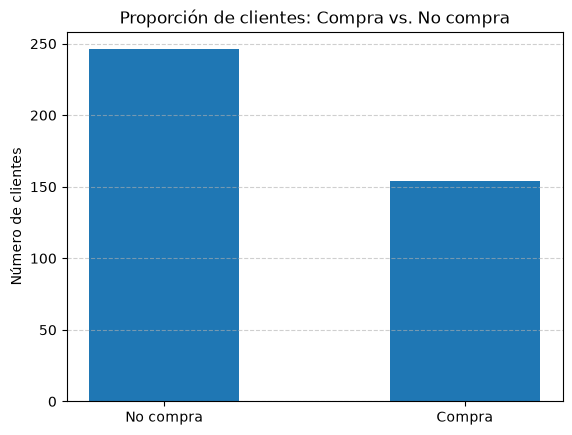

In [69]:
conteo = df["compra_proximo_mes"].value_counts()

plt.bar(["No compra", "Compra"], conteo.values, width=0.5)
plt.title("Proporción de clientes: Compra vs. No compra")
plt.ylabel("Número de clientes")
plt.grid(axis="y", linestyle="--", alpha=0.6) 
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No, las clases no aparecen con la misma frecuencia, existe un ligero desbalanceo hacia la clase negativa. La categoría "No compra" cuenta con casi 250 clientes, mientras que "Compra" registra poc más de 150 clientes, lo que supone una diferencia de casi 90 registros entre ambas.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [70]:
# TODO: describe() solo sobre las columnas indicadas
df[["edad", "ingresos_anuales", "gasto_mensual","num_compras","devoluciones"]].describe() #Muestra el resumen estadístico (media, desviación, min, max y cuartiles) de las columnas numéricas.

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** La mayoría tiene entre 33 y 59 años (mediana de 45), pero destaca un valor máximo atípico de 195 años que indica un error de registro.
- **ingresos_anuales:** Presenta 4 valores nulos y una distribución muy simétrica entre 9.000 y 82.925, con una media (36.441) y mediana (36.817) casi idénticas.
- **gasto_mensual:** Tiene 3 valores nulos y una ligera asimetría hacia la derecha, donde algunos gastos altos (hasta 260) elevan la media (69,09) por encima de la mediana (61,17).
- **num_compras:** Sin nulos y muy equilibrada, con una media de 8,2 compras y la mayoría de clientes concentrados entre 6 y 10 compras (rango de 2 a 17).
- **devoluciones:** Sin nulos y con valores bajos en general (media de 1,22 y máximo de 5), el 75 % de los clientes realiza 2 devoluciones o menos.

### Ejercicio 15 - Detectar algo sospechoso
1. **¿Hay algún valor poco razonable?** Sí, un valor máximo de **195**.
2. **¿En qué variable?** En la columna "edad".
3. **¿Por qué es sospechoso?** Porque es biológicamente imposible que un cliente tenga 195 años, lo que indica un claro error de captura o digitación (por ejemplo, haber escrito 195 en lugar de 95 o 19).
4. **¿Lo eliminarías inmediatamente?** No, no conviene borrar toda la fila de golpe porque perderíamos información válida del resto de columnas de ese cliente (ingresos, compras, gasto, etc.).
5. **¿Qué comprobarías antes?** Revisaría cuántos registros tienen edades anómalas (por ejemplo, mayores de 100 años), inspeccionaría el resto de datos de esa fila para ver si el registro es coherente y decidiría si imputar el valor (con la mediana o como nulo) o corregirlo si hay un patrón claro.

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

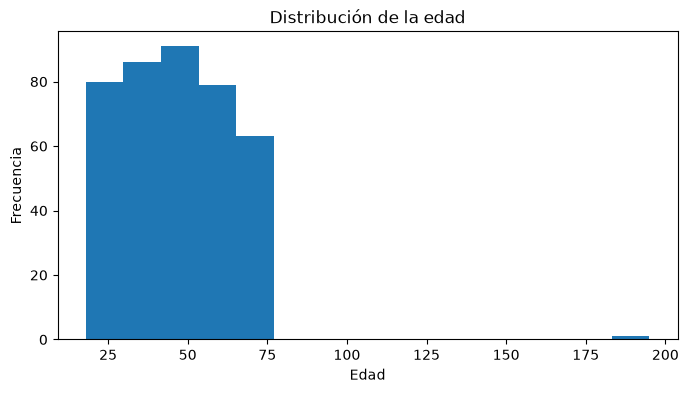

In [71]:
# TODO: histograma de edad

plt.figure(figsize=(8,4))
plt.hist(df["edad"],bins=15)
plt.title("Distribución de la edad")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

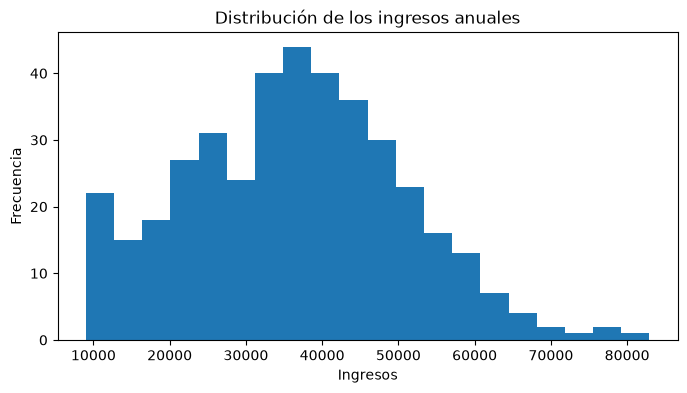

In [72]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,4))
plt.hist(df["ingresos_anuales"], bins=20)
plt.title("Distribución de los ingresos anuales")
plt.xlabel("Ingresos")
plt.ylabel("Frecuencia")
plt.show()

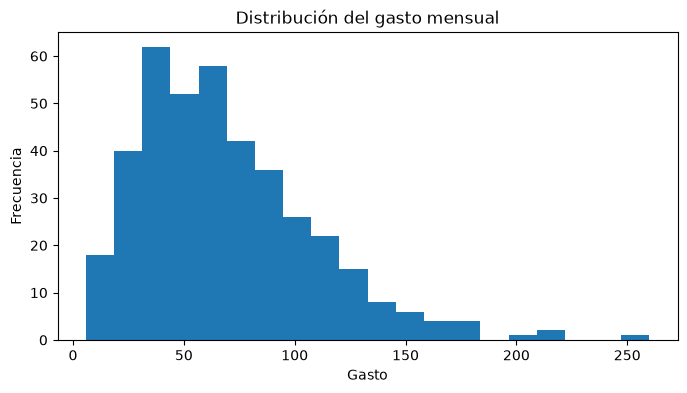

In [73]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,4))
plt.hist(df["gasto_mensual"], bins=20)
plt.title("Distribución del gasto mensual")
plt.xlabel("Gasto")
plt.ylabel("Frecuencia")
plt.show()

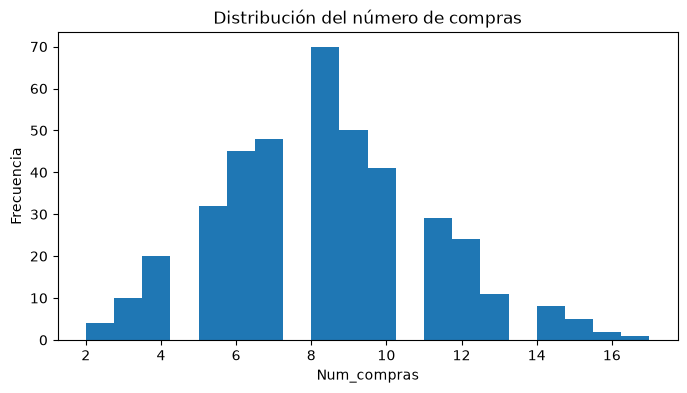

In [ ]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,4))
plt.hist(df["num_compras"], bins=20)
plt.title("Distribución del número de compras")
plt.xlabel("Num_compras")
plt.ylabel("Frecuencia")
plt.show()

### Observaciones
- **edad:** En la edad hay un outlier
- **ingresos_anuales:** Hay asimetria positiva.
- **gasto_mensual:** Hay una regresión positiva.
- **num_compras:** Distribución simétrica en forma de campana

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

- **Target:** `compra_proximo_mes` (es la variable objetivo que queremos predecir para cada cliente).
- **¿Existe \(y\)?:** Sí, contamos con esta columna etiquetada en el dataset histórico.
- **Supervisado / no supervisado:** Aprendizaje supervisado.
- **Clasificación / regresión / clustering:** Clasificación.
- **Binaria / multiclase:** Binaria.

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. **¿Cuál sería \(y\)?** La columna `gasto_proximo_mes`.
2. **¿Qué tipo de variable?** Numérica continua (cuantitativa), ya que representa dinero y puede tomar distintos valores decimales dentro de un rango.
3. **¿Supervisado?** Sí, es aprendizaje supervisado porque disponemos de datos históricos etiquetados con el gasto real (\(y\)) para entrenar al modelo.
4. **¿Clasificación o regresión?** Regresión.
5. **¿Por qué?** Porque el objetivo no es asignar el cliente a una categoría cerrada, sino predecir una cantidad numérica continua (un importe monetario exacto).

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. **¿Existe etiqueta de grupo?** No.
2. **¿Necesitamos \(y\)?** No, solo trabajamos con las características de entrada (\(X\)).
3. **¿Supervisado o no supervisado?** No supervisado.
4. **¿Qué técnica usaríamos?** Clustering o agrupamiento (por ejemplo, K-Means).
5. **¿Qué variables podrían describir los grupos?** `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones` (variables que definen el perfil y comportamiento de compra del cliente).

## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Porque el rol de una variable no es fijo, sino que depende del objetivo del problema de negocio que queramos resolver en cada momento

### Ejercicio 21 - ¿Qué está mal aquí?
**Respuesta:** No estoy de acuerdo. Aunque ha separado bien la variable objetivo y, antes de usar X revisaría varias cuestiones clave:

1. **Columnas identificadoras o irrelevantes:** Si existe una columna como `id_cliente`, no aporta patrones útiles para predecir y hará que el modelo memorice datos en lugar de generalizar.
2. **Valores nulos y datos atípicos:** Hay columnas con valores faltantes (como `ingresos_anuales` o `gasto_mensual`) y valores erróneos (como la edad de 195 años) que deben limpiarse o imputarse antes de entrenar.
3. **Tipos de datos (variables categóricas):** Si hay columnas de texto (como género, ciudad o categoría), muchos algoritmos no pueden procesarlas directamente sin antes codificarlas a formato numérico.

## Parte 11 - Ficha técnica
### Ejercicio 22

### FICHA DEL DATASET
- **Nombre:** Clientes e-commerce
- **Número de muestras:** 400
- **Número de columnas:** [Revisar con `df.shape[1]`]
- **Unidad de observación:** Cada cliente (un registro por cliente)
- **Identificador:** [Revisar nombre exacto, ej. `id_cliente`]
- **Target:** `compra_proximo_mes`
- **Tipo de target:** Binaria (categórica / discreta: `0` y `1`)
- **Número de features candidatas:** [Total de columnas menos ID y Target]
- **Features numéricas:** `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`
- **Features categóricas nominales:** [Revisar columnas de texto, ej. `genero`, `ciudad`...]
- **Features ordinales:** [Revisar si existe alguna como `nivel_fidelidad`, o poner "Ninguna"]
- **Datos etiquetados:** Sí
- **Valores ausentes:** Sí (en `ingresos_anuales` [4] y `gasto_mensual` [3])
- **Problema principal:** Predecir si un cliente realizará una compra el próximo mes
- **Tipo de aprendizaje:** Supervisado
- **Tipo de tarea:** Clasificación binaria

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
El dataset analizado cuenta con una muestra de 400 registros, donde cada fila representa a un cliente distinto dentro de las dimensiones totales de la tabla. A la hora de preparar los datos, hay que distinguir entre el total de columnas y las features reales ($X$) que usaremos para entrenar, ya que conviene descartar el identificador de cliente porque no aporta información útil para predecir y solo haría que el modelo memorice casos concretos. Entre las variables disponibles tenemos atributos numéricos (como `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`) junto a otras variables categóricas que habrá que transformar a números antes de modelar. Nuestra variable objetivo o target ($y$) es `compra_proximo_mes`, lo que confirma que trabajamos con datos etiquetados. Al revisar la calidad del dataset vemos algunos valores ausentes en `ingresos_anuales` (4 nulos) y `gasto_mensual` (3 nulos), además de un error evidente en `edad` con un valor máximo de 195 años que tendremos que corregir. En cuanto a las distribuciones, los ingresos están bastante equilibrados, mientras que el gasto mensual presenta cierta asimetría hacia valores altos y la variable objetivo muestra un ligero desbalanceo (alrededor de un 61,5 % de clientes que no compran frente a un 38,5 % que sí). Con todo esto, una vez limpios y preparados los datos, estamos ante un problema de aprendizaje supervisado de clasificación binaria.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [ ]:
# TODO: ampliación opcional

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`